## Broad bidirectional traffic flow (Flag 21)

### Dataset Overview
Constructed northbound and southbound traffic in an established offshore corridor west of Jutland, with stable passages and short manoeuvring phases.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze how vessels organize and adjust their movements within a broad bidirectional traffic flow.

Role: Maritime traffic analyst


Category: broad bidirectional traffic flow

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How are the two directional flows organized laterally?

#### Analysis action

Compare the lateral positions of northbound and southbound trajectories in the same corridor.

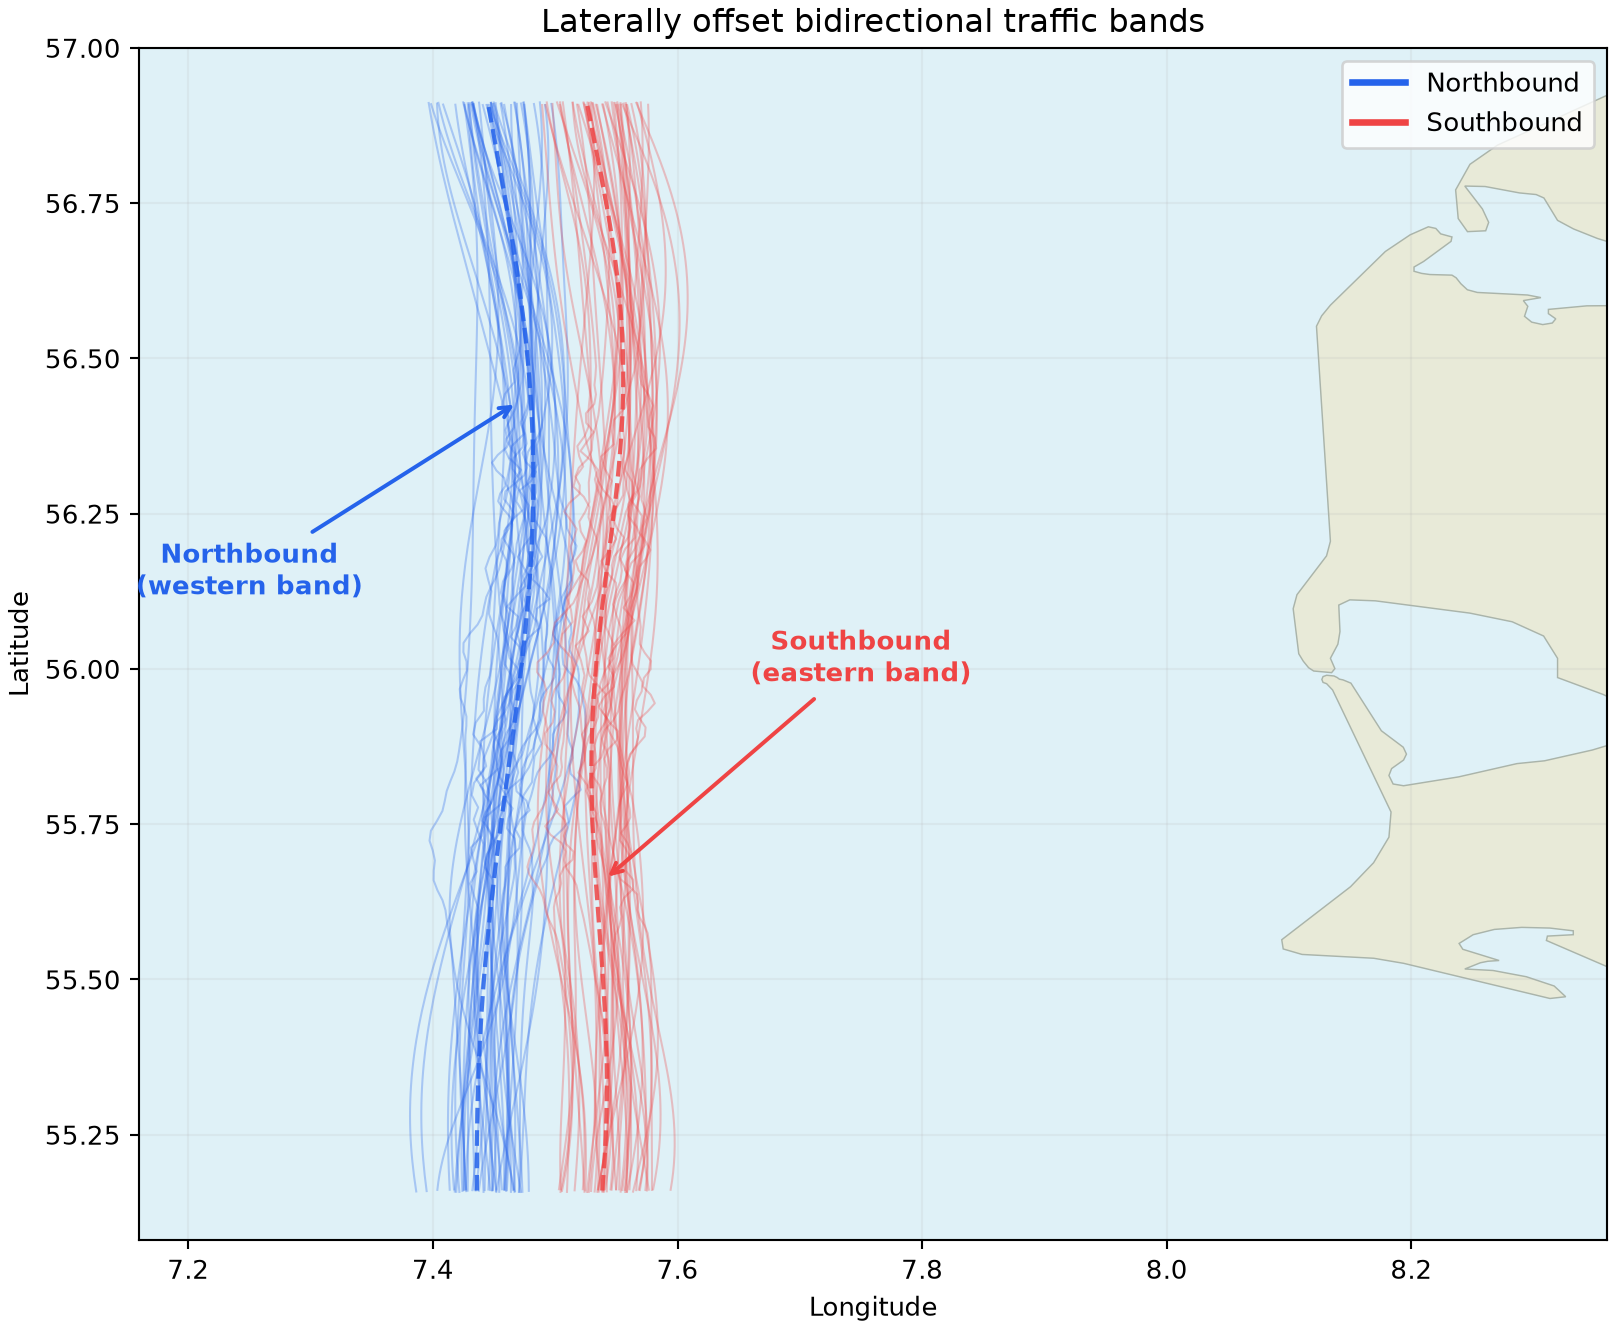

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby(['direction_flow','trajectory_id']).lon.mean().groupby(level=0).describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/bidirectional_bands.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "bidirectional_lateral_bands",
  "insight": "Northbound and southbound traffic forms two laterally offset movement bands, with northbound vessels concentrated farther west.",
  "insight_value": {
    "median_band_longitude": {
      "northbound": 7.4578,
      "southbound": 7.5532
    }
  },
  "plot": {
    "plot_type": "direction_colored_map",
    "title": "Bidirectional Traffic Bands",
    "file": "visualizations/bidirectional_bands.png",
    "description": "Compare the lateral positions of northbound and southbound trajectories in the same corridor."
  },
  "question": "How are the two directional flows organized laterally?",
  "actionable_insight": "Compare the lateral positions of northbound and southbound trajectories in the same corridor.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby(['direction_flow','trajectory_id']).lon.mean().groupby(level=0).describe())",
  "insight_type": "overall_pattern",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "vessel_id"
  ]
}

### **Question 2**: How are stable periods interrupted by short manoeuvring phases?

#### Analysis action

Compare speed, COG variation, and lateral position inside and outside short manoeuvring phases.

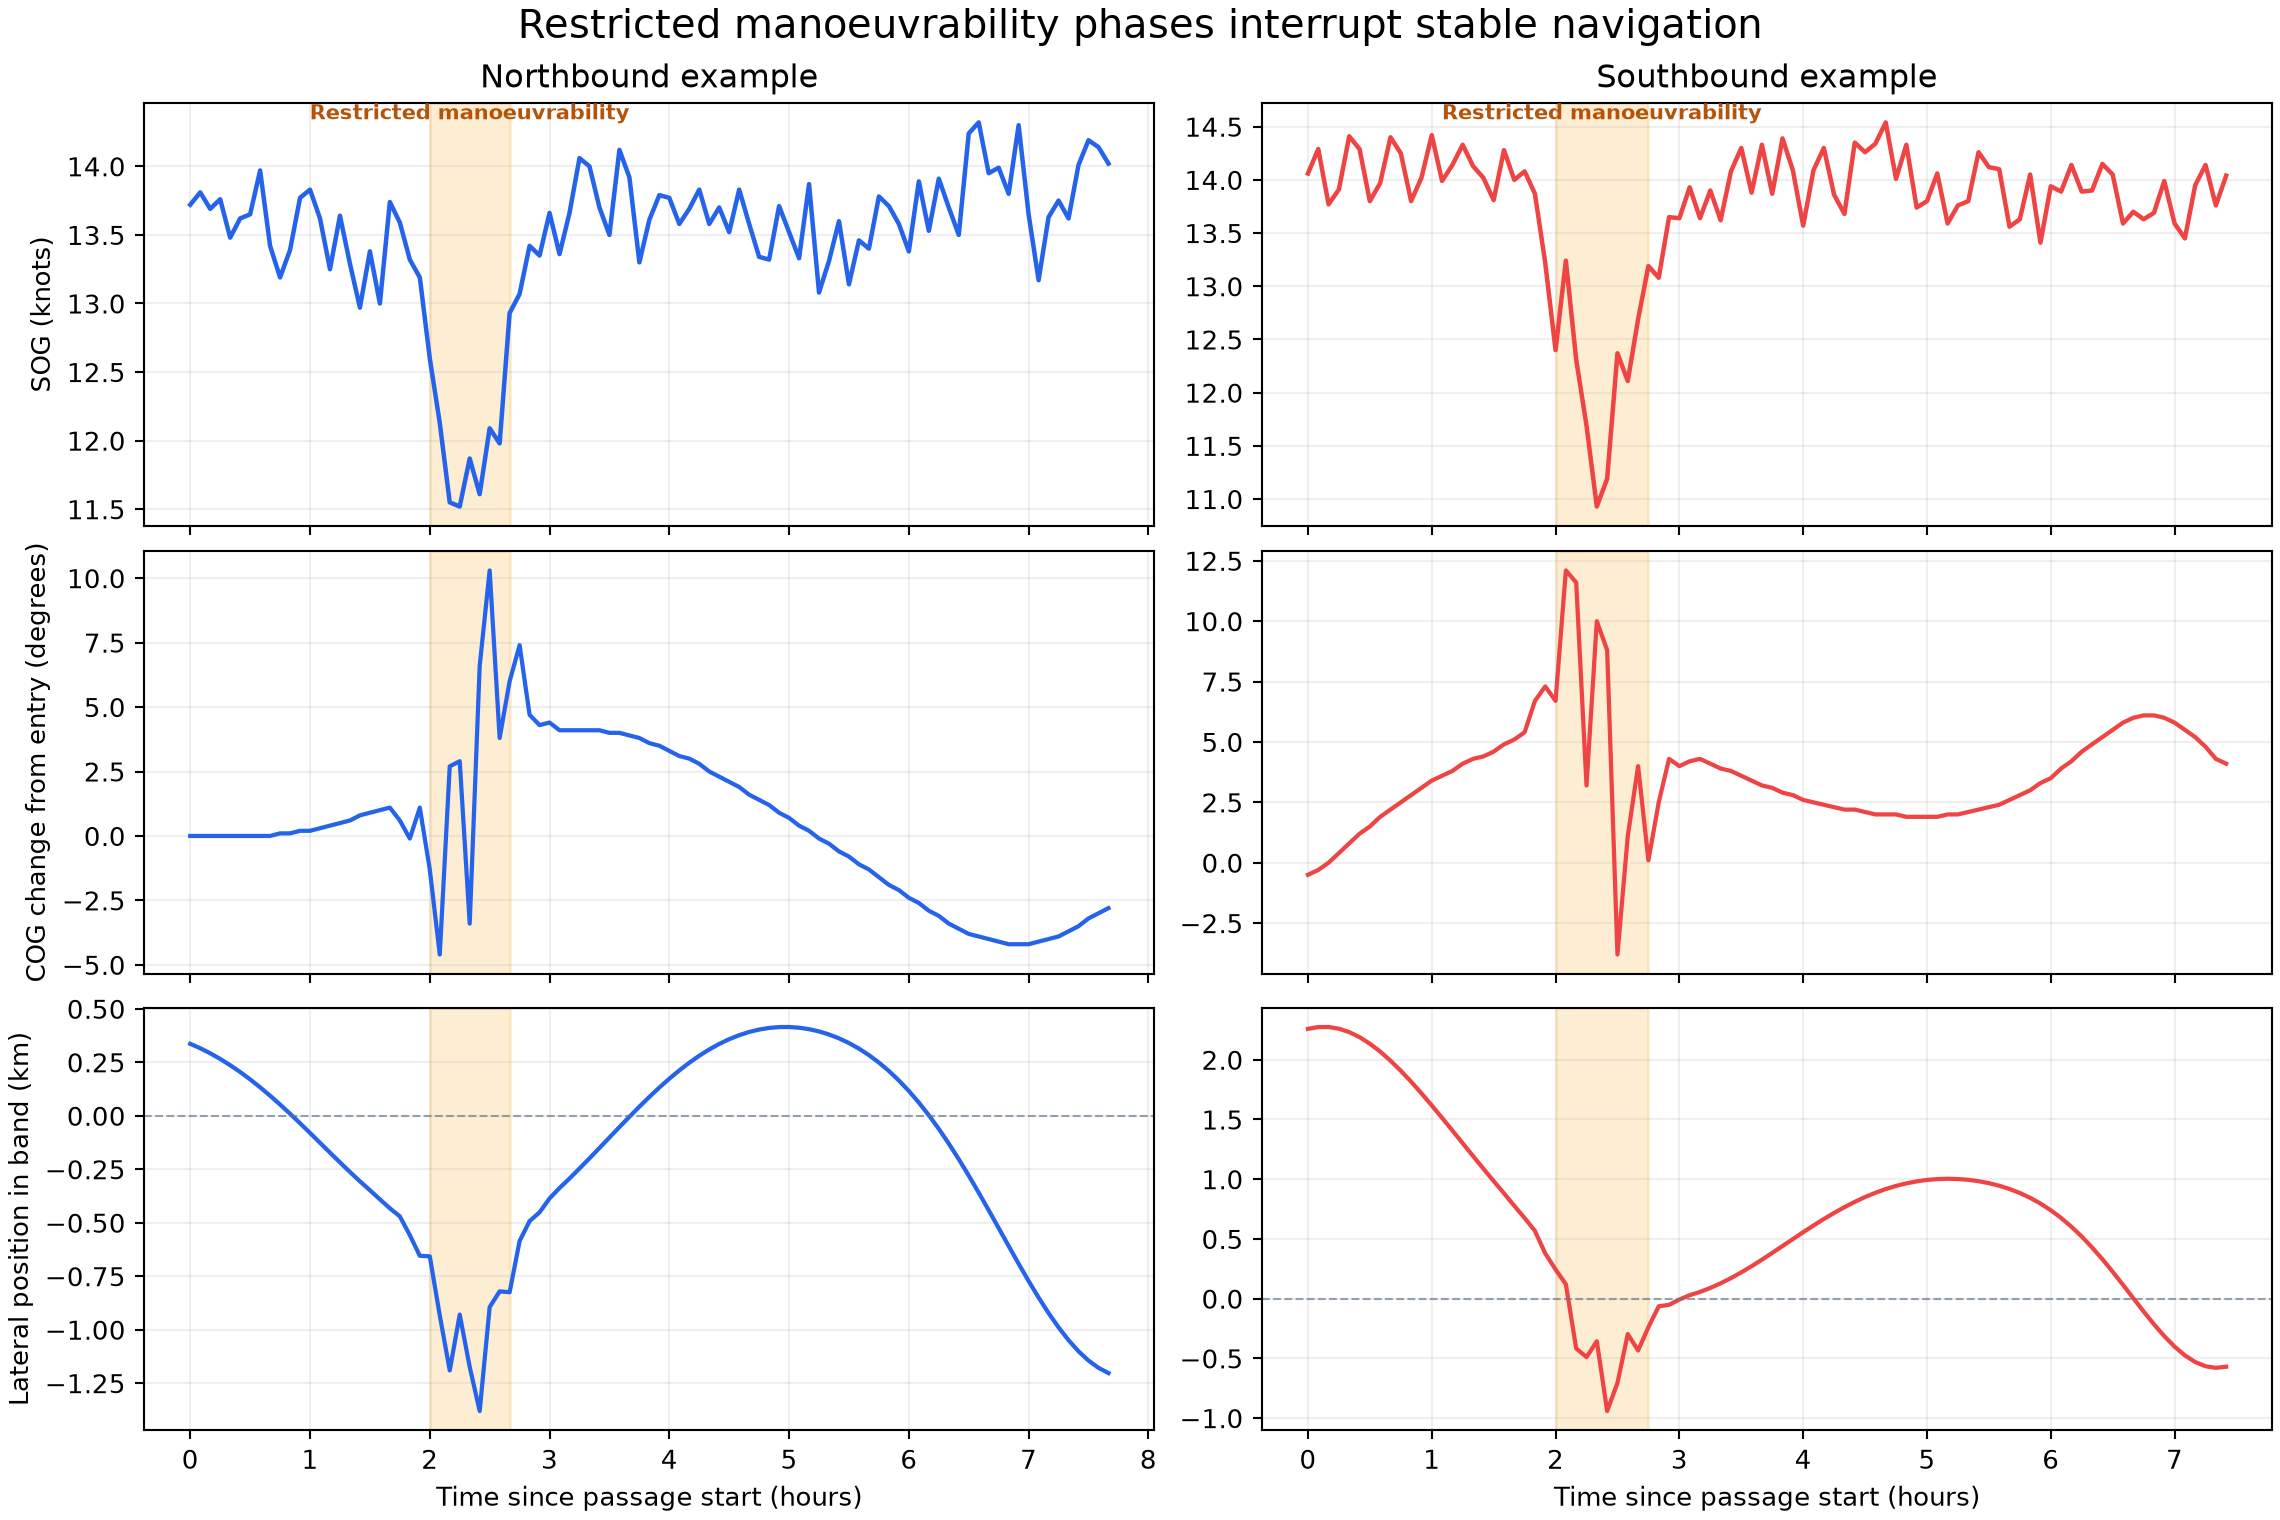

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby(['movement_phase','nav_status']).sog_knots.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/stable_manoeuvring_phases.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "stable_and_manoeuvring_phases",
  "insight": "Most vessels maintain stable COG and lateral position for long periods, interrupted by short manoeuvring phases with lower speed and greater directional variation before stable navigation resumes.",
  "insight_value": {
    "vessels_with_manoeuvre": 71,
    "total_vessels": 90,
    "phase_nav_status": {
      "stable": "Under way using engine",
      "manoeuvring": "Restricted manoeuvrability"
    },
    "median_phase_speed_knots": {
      "stable": 11.57,
      "manoeuvring": 9.0
    },
    "median_phase_direction_change_deg": {
      "stable": 0.1,
      "manoeuvring": 4.05
    }
  },
  "plot": {
    "plot_type": "aligned_phase_profiles",
    "title": "Stable Navigation and Short Manoeuvres",
    "file": "visualizations/stable_manoeuvring_phases.png",
    "description": "Compare speed, COG variation, and lateral position inside and outside short manoeuvring phases."
  },
  "question": "How are stable periods interrupted by short manoeuvring phases?",
  "actionable_insight": "Compare speed, COG variation, and lateral position inside and outside short manoeuvring phases.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby(['movement_phase','nav_status']).sog_knots.describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "course_over_ground",
    "point_speed",
    "vessel_id",
    "navigation_status"
  ]
}

### **Question 3**: How is passage speed associated with lateral dispersion?

#### Analysis action

Compare continuous passage speed with within-band lateral dispersion separately for both directions.

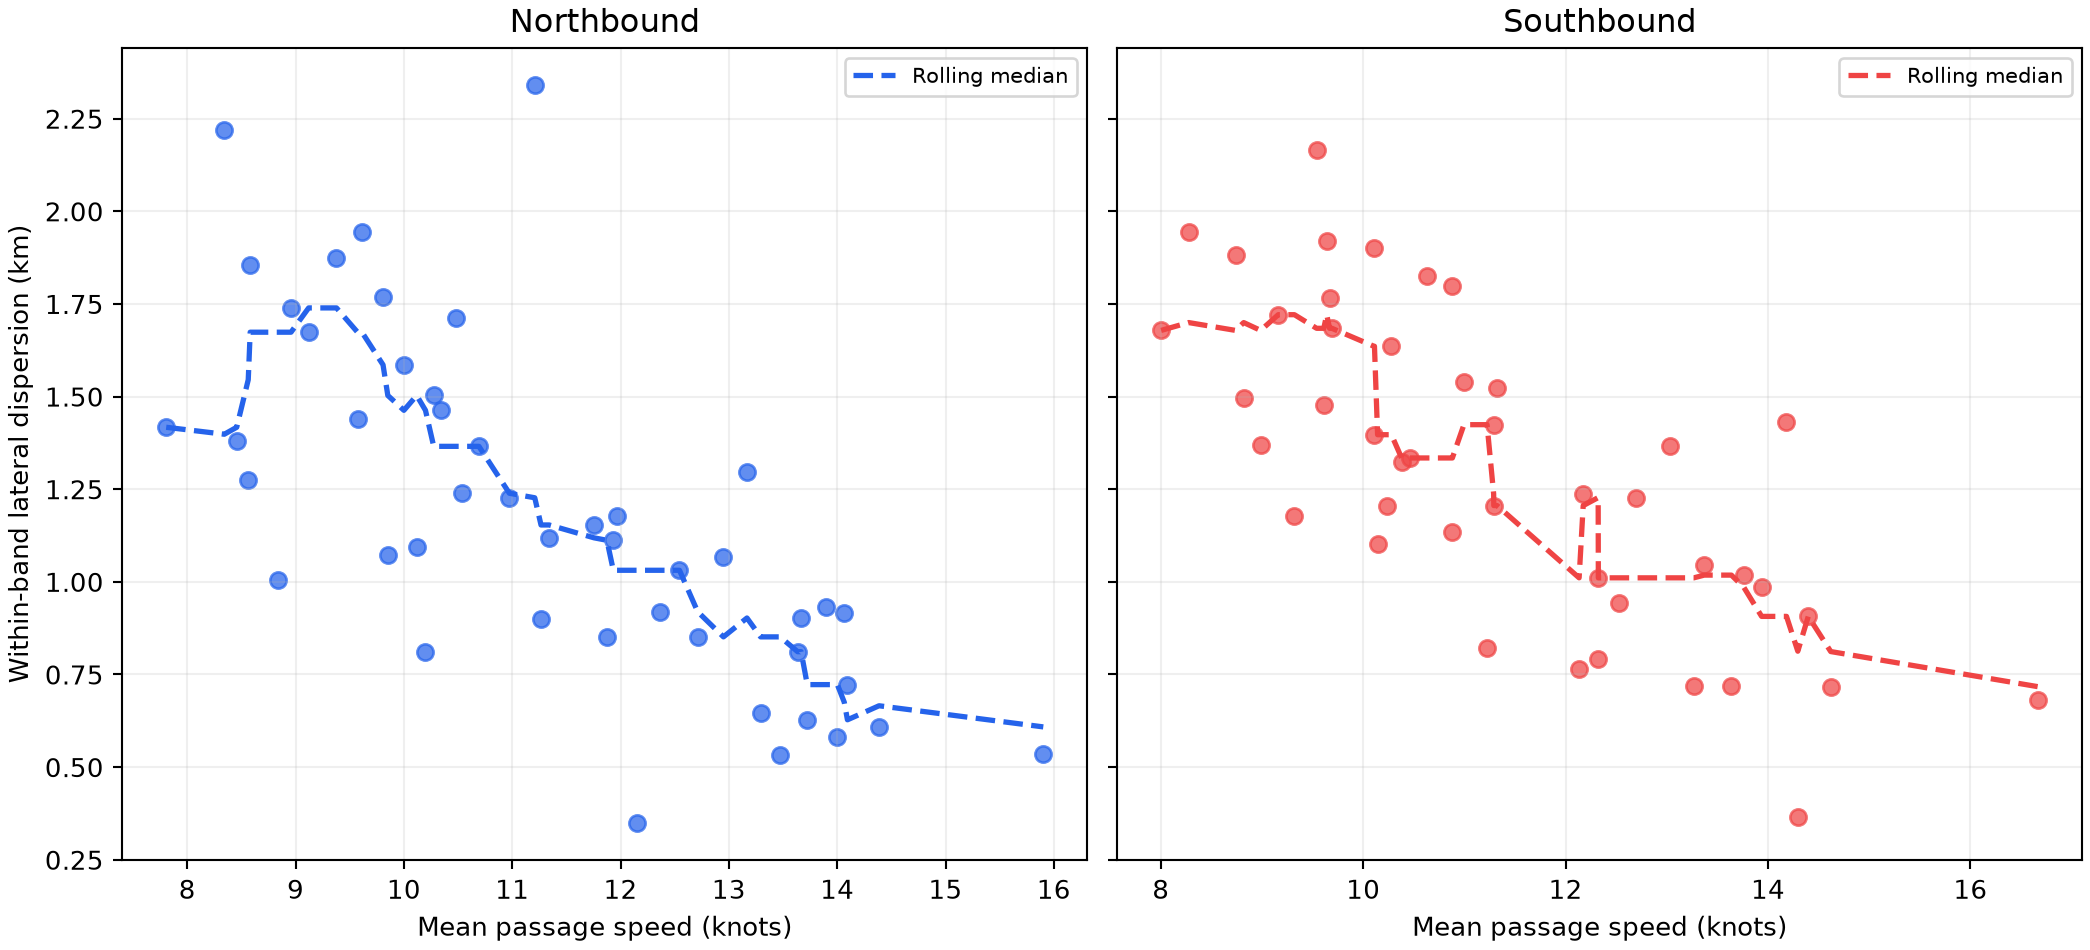

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby(['direction_flow','trajectory_id']).agg(speed=('sog_knots','mean'),lon_sd=('lon','std')))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_lateral_dispersion.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_lateral_dispersion",
  "insight": "Lower-speed passages show greater lateral dispersion within both directional flows, while faster passages remain more tightly concentrated within their dominant movement bands.",
  "insight_value": {
    "spearman_rho": {
      "northbound": -0.755,
      "southbound": -0.739
    },
    "median_lateral_dispersion_km": {
      "slower_third": 1.68,
      "faster_third": 0.9
    }
  },
  "plot": {
    "plot_type": "faceted_scatter",
    "title": "Speed and Lateral Dispersion",
    "file": "visualizations/speed_lateral_dispersion.png",
    "description": "Compare continuous passage speed with within-band lateral dispersion separately for both directions."
  },
  "question": "How is passage speed associated with lateral dispersion?",
  "actionable_insight": "Compare continuous passage speed with within-band lateral dispersion separately for both directions.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby(['direction_flow','trajectory_id']).agg(speed=('sog_knots','mean'),lon_sd=('lon','std'))) ",
  "insight_type": "factor_relationship",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "point_speed",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 21)

Northbound and southbound traffic forms two laterally offset movement bands, with northbound vessels concentrated farther west. Most vessels maintain stable COG and lateral position for long periods, interrupted by short manoeuvring phases with lower speed and greater directional variation before stable navigation resumes. Lower-speed passages show greater lateral dispersion within both directional flows, while faster passages remain more tightly concentrated within their dominant movement bands.